# Time Series Models: AR, MA, ARIMA

## Autoregressive Model (AR)

**Definition**:  
An AR model regresses a variable on its own past values:

$$
Y_t = \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \dots + \phi_p Y_{t-p} + u_t
$$


## 2. Moving Average Model (MA)

**Definition**:  
An MA model expresses \( Y_t \) as a function of past shocks:

$$
Y_t = u_t + \theta_1 u_{t-1} + \theta_2 u_{t-2} + \dots + \theta_q u_{t-q}
$$

## 3. ARIMA Model (Autoregressive Integrated Moving Average)

**Definition**:  
ARIMA(p, d, q) models combine:

- **AR(p)**: Autoregressive part  
- **I(d)**: Integrated part (number of differences to make the series stationary)  
- **MA(q)**: Moving average part  

The general form:

$$
\Delta^d Y_t = \phi_1 \Delta^d Y_{t-1} + \dots + \phi_p \Delta^d Y_{t-p} + u_t + \theta_1 u_{t-1} + \dots + \theta_q u_{t-q}
$$

**Use**: Models non-stationary data that becomes stationary after differencing.

## 4. Augmented Dickey-Fuller (ADF) Test

Used to test whether a time series is **stationary** or has a **unit root**.

### Hypotheses:
$$
( H_0 ): non-stationary
$$
$$
( H_1 ):  stationary
$$

**ADF**
$$
Delta Y_t = \alpha + \beta t + \gamma Y_{t-1} + \sum_{i=1}^p \delta_i \Delta Y_{t-i} + u_t
$$
We test:

$$
- ( H_0: \gamma = 1 ) (unit root)
- ( H_1: \gamma < 1 ) (stationary)
$$
### Decision Rule critical value:

- If ADF test statistic < critical value → **Reject \( H_0 \)** → Stationary  
- If ADF test statistic > critical value → **Fail to reject \( H_0 \)** → Unit root (non-stationary)

Note: Critical values come from the **Dickey-Fuller distribution**, not the standard t-distribution.

### Decision Rule p-value:
- If p-value < 0.05 → **Reject \( H_0 \)** → Stationary  
- If p-value > 0.05 > critical value → **Fail to reject \( H_0 \)** → Unit root (non-stationary)
---

## Definition

A **white noise process** $(\{u_t\})$ is a sequence of random variables satisfying:

1. **Zero Mean**  
   $$
   \mathbb{E}[u_t] = 0
   $$

2. **Constant Variance (Homoskedasticity)**  
   $$
   \mathbb{E}[u_t^2] = \sigma^2 < \infty
   $$

3. **No Serial Correlation (Uncorrelatedness)**  
   $$
   \mathbb{E}[u_t u_s] = 0 \quad \text{for } t \neq s
   $$
---
- **Model Diagnostics**  
  Residuals from a correctly specified model should behave like white noise. If they don't, the model is likely misspecified.

- **Innovation Processes in Time Series**  
  In ARMA models:
  $$
    X_t = \phi X_{t-1} + u_t + \theta u_{t-1}, \quad u_t \sim \text{white noise}
  $$
---

### 📊 ACF and PACF Patterns for ARIMA Models

| Model Type    | ACF Pattern                          | PACF Pattern                          |
|---------------|--------------------------------------|----------------------------------------|
| **AR(p)**     | Tails off (Geometric decay)          | Significant up to lag **p**, then cuts off |
| **MA(q)**     | Significant up to lag **q**, then cuts off | Tails off (Geometric decay)          |
| **ARMA(p, q)**| Tails off (Geometric decay)          | Tails off (Geometric decay)            |

In [6]:
#ACF: Autocorrelation
#PACF: Partial Autocorrelation

### ARIMA and SARIMA

**Import necessary Libraries**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sms
import pandas as pd
from datetime import datetime

**Read the dataset from Github**

In [2]:
url="https://raw.githubusercontent.com/brahzr/Time-series-Analysis/refs/heads/main/airline_passengers.csv"
df_airline=pd.read_csv(url)
df_airline.head()

,Month,Thousands of Passengers
0,1949-01,112.0
1,1949-02,118.0
2,1949-03,132.0
3,1949-04,129.0
4,1949-05,121.0


In [3]:
df_airline.tail()

,Month,Thousands of Passengers
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0
144,International airline passengers: monthly tota...,NaN


**Simple EDA**

In [4]:
#missing values
df_airline.isnull().sum()

Month                      0
Thousands of Passengers    1
dtype: int64

**Dealing with missing values**

In [20]:
#Method01
df_airline.dropna(inplace = True)

In [21]:
df_airline.tail()

,Month,Thousands of Passengers
139,1960-08,606.0
140,1960-09,508.0
141,1960-10,461.0
142,1960-11,390.0
143,1960-12,432.0


In [22]:
df_airline.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Month                    144 non-null    str    
 1   Thousands of Passengers  144 non-null    float64
dtypes: float64(1), str(1)
memory usage: 2.4 KB


In [23]:
df_airline["Month"]= pd.to_datetime(df_airline["Month"])

In [24]:
df_airline.info()

<class 'pandas.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Month                    144 non-null    datetime64[us]
 1   Thousands of Passengers  144 non-null    float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 2.4 KB


<Axes: >

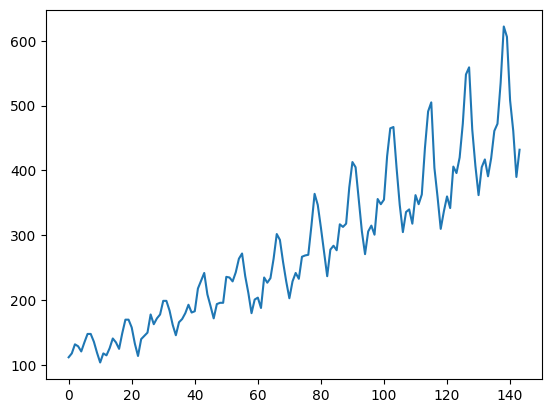

In [25]:
df_airline["Thousands of Passengers"].plot()

In [26]:
df_airline.set_index('Month',inplace=True)

<Axes: xlabel='Month'>

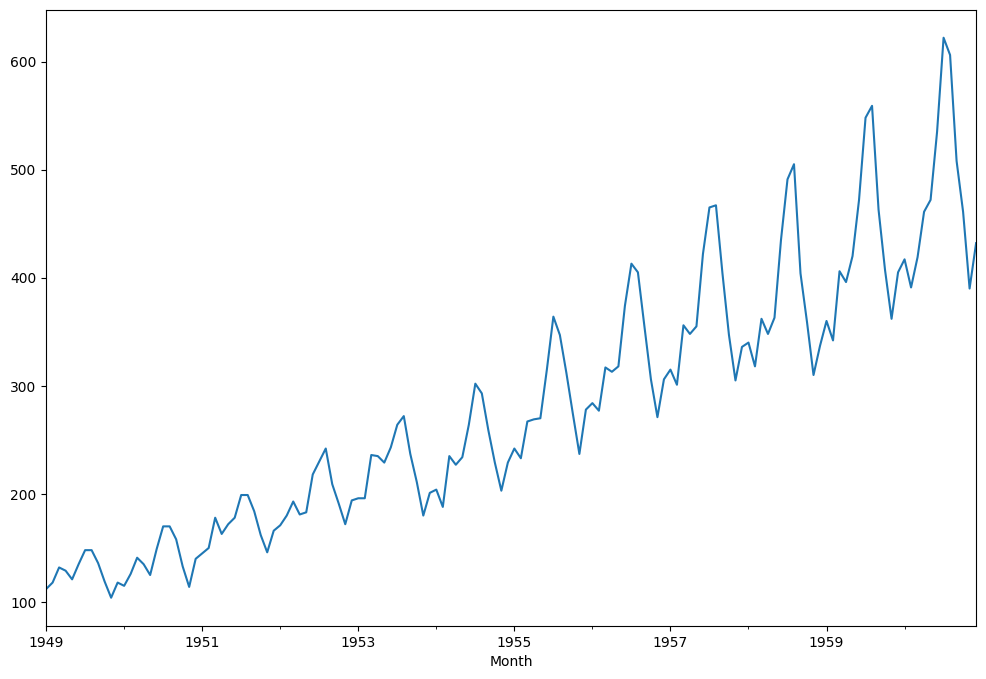

In [27]:
df_airline["Thousands of Passengers"].plot(figsize = (12,8))

In [28]:
df_airline["Thousands of Passengers"].describe()

count    144.000000
mean     280.298611
std      119.966317
min      104.000000
25%      180.000000
50%      265.500000
75%      360.500000
max      622.000000
Name: Thousands of Passengers, dtype: float64

**Stationary Analysis**

In [32]:
from statsmodels.tsa.stattools import adfuller, kpss

---

In [33]:
def adf_test(series):
    result = adfuller(series)
    print(result)
    print("ADF Statistics: {}".format(result[0]))
    print("p- value: {}".format(result[1]))
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary")
    else:
        print("weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary ")

### kpss Hypotheses:
$$
( H_0 ): stationary
$$
$$
( H_1 ): non stationary
$$

In [34]:
def kpss_test(series):
    result = kpss(series)
    print(result)
    print("kpss Statistics: {}".format(result[0]))
    print("p- value: {}".format(result[1]))
    if result[1] <= 0.05:
        print("strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary")
    else:
        print("weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary ")

In [35]:
adf_test(df_airline["Thousands of Passengers"])

(np.float64(0.8153688792060482), np.float64(0.991880243437641), 13, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(996.692930839019))
ADF Statistics: 0.8153688792060482
p- value: 0.991880243437641
weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary 


In [36]:
kpss_test(df_airline["Thousands of Passengers"])

(np.float64(1.6513122354165206), np.float64(0.01), 8, {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})
kpss Statistics: 1.6513122354165206
p- value: 0.01
strong evidence against the null hypothesis, time series has a unit root. indicating it is non-stationary


C:\Users\Brahim\AppData\Local\Temp\ipykernel_17376\355439486.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(series)


In [37]:
## Use Techniques Differencing
df_airline["Passengers First Difference"]=df_airline["Thousands of Passengers"]-df_airline["Thousands of Passengers"].shift(1)
df_airline.head()

,Thousands of Passengers,Passengers First Difference
Month,,
1949-01-01,112.0,NaN
1949-02-01,118.0,6.0
1949-03-01,132.0,14.0
1949-04-01,129.0,-3.0
1949-05-01,121.0,-8.0


In [39]:
adf_test(df_airline["Passengers First Difference"].dropna())

(np.float64(-2.8292668241699994), np.float64(0.0542132902838255), 12, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(988.5069317854084))
ADF Statistics: -2.8292668241699994
p- value: 0.0542132902838255
weak evidence against null hypothesis, time series has a unit root, indicating it is non-stationary 


In [40]:
kpss_test(df_airline["Passengers First Difference"].dropna())

(np.float64(0.023897614400183967), np.float64(0.1), 7, {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})
kpss Statistics: 0.023897614400183967
p- value: 0.1
weak evidence against null hypothesis, fails to reject the null hypothesis. indicating it is stationary 


C:\Users\Brahim\AppData\Local\Temp\ipykernel_17376\355439486.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series)


In [ ]:
pip install arch

In [41]:
from arch.unitroot import PhillipsPerron

In [42]:
pp = PhillipsPerron(df_airline['Passengers First Difference'].dropna())
print(pp.summary())

     Phillips-Perron Test (Z-tau)    
Test Statistic                 -8.937
P-value                         0.000
Lags                               14
-------------------------------------

Trend: Constant
Critical Values: -3.48 (1%), -2.88 (5%), -2.58 (10%)
Null Hypothesis: The process contains a unit root.
Alternative Hypothesis: The process is weakly stationary.


ARIMA(p,d,q) <br>
d = 1

**ACF and PACF ARIMA**

In [43]:
from statsmodels.graphics.tsaplots import acf, pacf, plot_acf,plot_pacf

In [45]:
acf_values = acf(df_airline["Passengers First Difference"].dropna(), nlags=12)

print(acf_values)

[ 1.          0.30285526 -0.10214755 -0.24127349 -0.30040158 -0.09407271
 -0.07844257 -0.0923622  -0.29480158 -0.19177821 -0.10491707  0.28293105
  0.82917786]


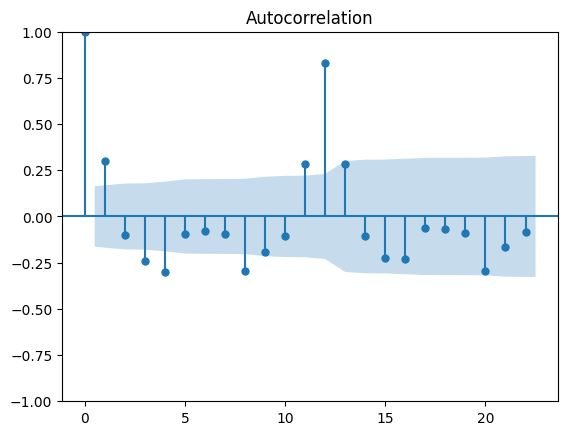

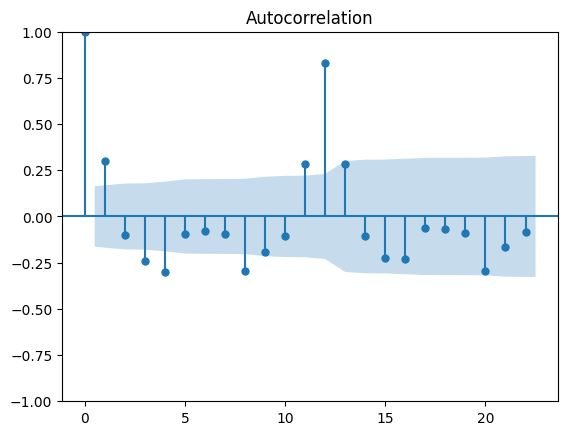

In [47]:
plot_acf(df_airline["Passengers First Difference"].dropna())

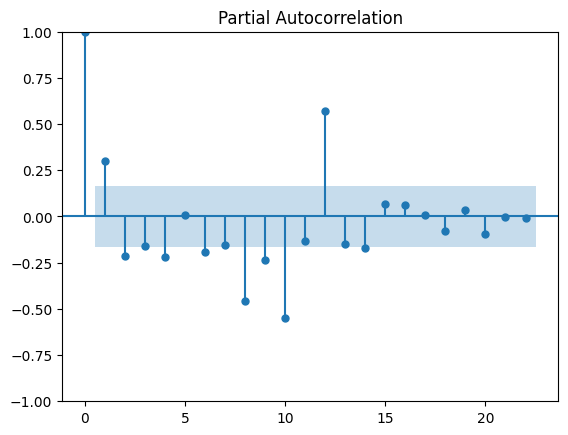

In [49]:
result = plot_pacf(df_airline["Passengers First Difference"].dropna())

ARIMA(1,2 ,1 ), ARIMA(11,2,12), ARIMA(10,2,2)........etc

Less AIC <br>
Bigger R squared <br>
Less MSE (Mean Squared Error)

---

#### 2.Moddeling ARIMA

In [51]:
## create a ARIMA model
from statsmodels.tsa.arima.model import ARIMA

In [54]:
model_ARIMA = ARIMA(df_airline['Thousands of Passengers'],order=(4,1,3)) #many models p = 11, q=12

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [55]:
model_Arima_fit=model_ARIMA.fit()

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [56]:
print(model_Arima_fit.summary())

                                  SARIMAX Results                                  
Dep. Variable:     Thousands of Passengers   No. Observations:                  144
Model:                      ARIMA(4, 1, 3)   Log Likelihood                -674.913
Date:                     Mon, 02 Mar 2026   AIC                           1365.825
Time:                             13:30:48   BIC                           1389.528
Sample:                         01-01-1949   HQIC                          1375.457
                              - 12-01-1960                                         
Covariance Type:                       opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5582      0.117     -4.782      0.000      -0.787      -0.329
ar.L2          0.4935      0.113      4.375      0.000       0.272       0.715
ar.L3       

In [63]:
#ARIMA(11,2,12), AIC = 661.252
#ARIMA(1,2,1), AIC = 741.674

**Semecting Creteria**

#### 3.Prediction

In [57]:
pred=model_Arima_fit.predict()
residuals=df_airline["Thousands of Passengers"]-pred #Y - Y_hat

In [58]:
table = pd.DataFrame({"Real Data": df_airline["Thousands of Passengers"],
"Prediction": pred,
"Residuals": residuals})

print(table.head(10))

            Real Data  Prediction   Residuals
1949-01-01      112.0    0.000000  112.000000
1949-02-01      118.0  112.039908    5.960092
1949-03-01      132.0  119.858646   12.141354
1949-04-01      129.0  136.007000   -7.007000
1949-05-01      121.0  124.632247   -3.632247
1949-06-01      135.0  115.985944   19.014056
1949-07-01      148.0  136.997627   11.002373
1949-08-01      148.0  149.791577   -1.791577
1949-09-01      136.0  141.296778   -5.296778
1949-10-01      119.0  126.542571   -7.542571


In [59]:
print(table.tail(10))

            Real Data  Prediction  Residuals
1960-03-01      419.0  412.983867   6.016133
1960-04-01      461.0  406.337310  54.662690
1960-05-01      472.0  502.663164 -30.663164
1960-06-01      535.0  440.800995  94.199005
1960-07-01      622.0  558.074196  63.925804
1960-08-01      606.0  611.964166  -5.964166
1960-09-01      508.0  549.230200 -41.230200
1960-10-01      461.0  451.474633   9.525367
1960-11-01      390.0  427.629227 -37.629227
1960-12-01      432.0  393.635849  38.364151


**Residuals Diagnostics**

<Axes: xlabel='Month'>

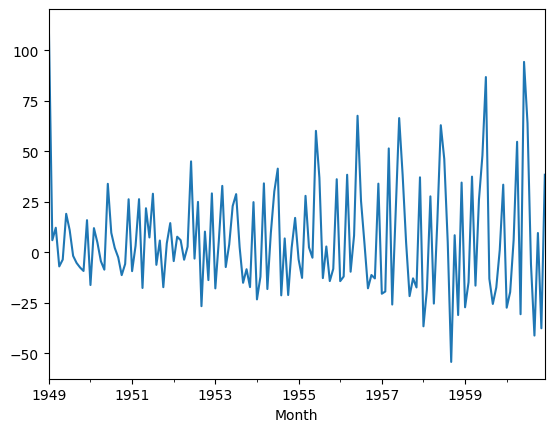

In [60]:
model_Arima_fit.resid.plot()

<Axes: ylabel='Density'>

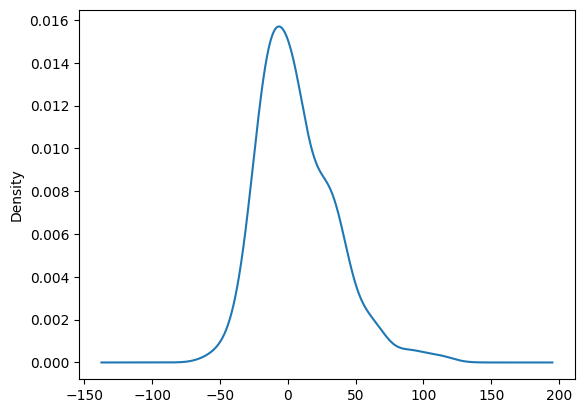

In [61]:
model_Arima_fit.resid.plot(kind = "kde")

In [63]:
#Jarqua Bera
stats.jarque_bera(model_Arima_fit.resid)

SignificanceResult(statistic=np.float64(30.558694055789758), pvalue=np.float64(2.3134701414642165e-07))

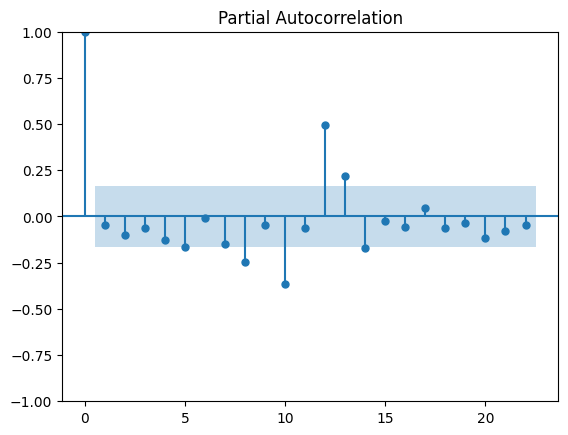

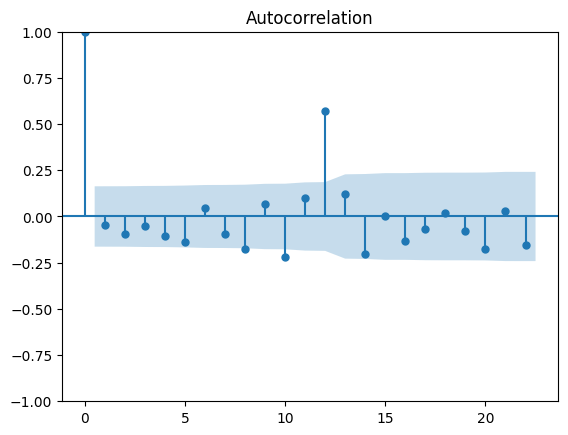

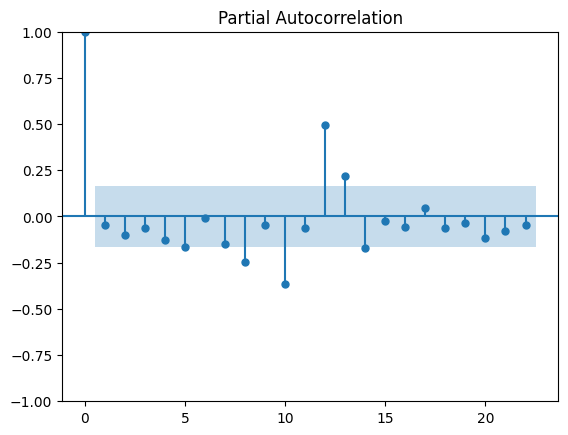

In [64]:
plot_acf(residuals)
plot_pacf(residuals)

In [65]:
df_airline["Predicted_ARIMA"]= pred
df_airline.head()

,Thousands of Passengers,Passengers First Difference,Predicted_ARIMA
Month,,,
1949-01-01,112.0,NaN,0.000000
1949-02-01,118.0,6.0,112.039908
1949-03-01,132.0,14.0,119.858646
1949-04-01,129.0,-3.0,136.007000
1949-05-01,121.0,-8.0,124.632247


<Axes: xlabel='Month'>

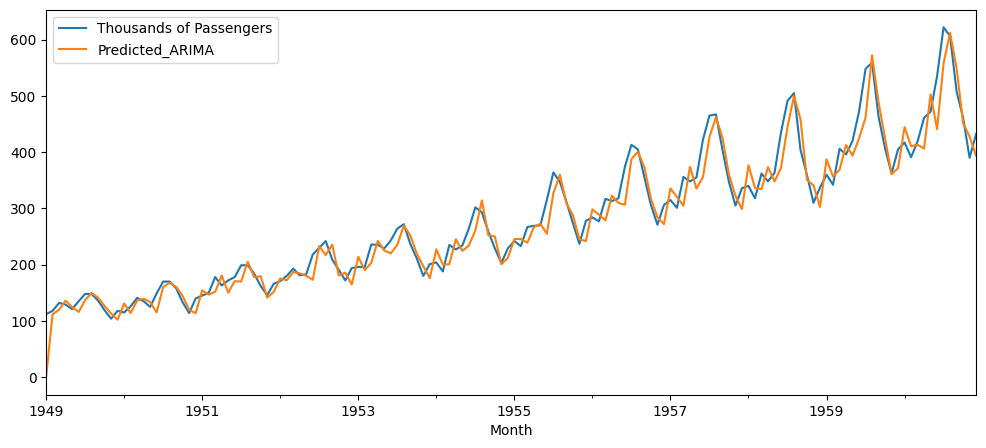

In [66]:
df_airline[["Thousands of Passengers","Predicted_ARIMA"]].plot(figsize = (12,5))

#### 4.Forecasting Future dates

In [67]:
from pandas.tseries.offsets import DateOffset
future_dates = [df_airline.index[-1] + DateOffset (months = x) for x in range(0, 24)]

In [68]:
future_date_dataset = pd.DataFrame(index = future_dates[1:], columns = df_airline.columns)
future_date_dataset.tail()

,Thousands of Passengers,Passengers First Difference,Predicted_ARIMA
1962-07-01,NaN,NaN,NaN
1962-08-01,NaN,NaN,NaN
1962-09-01,NaN,NaN,NaN
1962-10-01,NaN,NaN,NaN
1962-11-01,NaN,NaN,NaN


In [69]:
merged_df = pd.concat([df_airline, future_date_dataset])
merged_df.tail()

,Thousands of Passengers,Passengers First Difference,Predicted_ARIMA
1962-07-01,NaN,NaN,NaN
1962-08-01,NaN,NaN,NaN
1962-09-01,NaN,NaN,NaN
1962-10-01,NaN,NaN,NaN
1962-11-01,NaN,NaN,NaN


In [70]:
df_airline.tail()

,Thousands of Passengers,Passengers First Difference,Predicted_ARIMA
Month,,,
1960-08-01,606.0,-16.0,611.964166
1960-09-01,508.0,-98.0,549.230200
1960-10-01,461.0,-47.0,451.474633
1960-11-01,390.0,-71.0,427.629227
1960-12-01,432.0,42.0,393.635849


In [71]:
merged_df['forecast_arima'] = model_Arima_fit.predict(start ="1960-12-01", end = "1962-11-01", dynamic= True ) #31 months
merged_df

,Thousands of Passengers,Passengers First Difference,Predicted_ARIMA,forecast_arima
1949-01-01,112.0,NaN,0.0,NaN
1949-02-01,118.0,6.0,112.039908,NaN
1949-03-01,132.0,14.0,119.858646,NaN
1949-04-01,129.0,-3.0,136.007,NaN
1949-05-01,121.0,-8.0,124.632247,NaN
...,...,...,...,...
1962-07-01,NaN,NaN,NaN,466.405719
1962-08-01,NaN,NaN,NaN,462.599544
1962-09-01,NaN,NaN,NaN,464.127821
1962-10-01,NaN,NaN,NaN,465.514191


<Axes: >

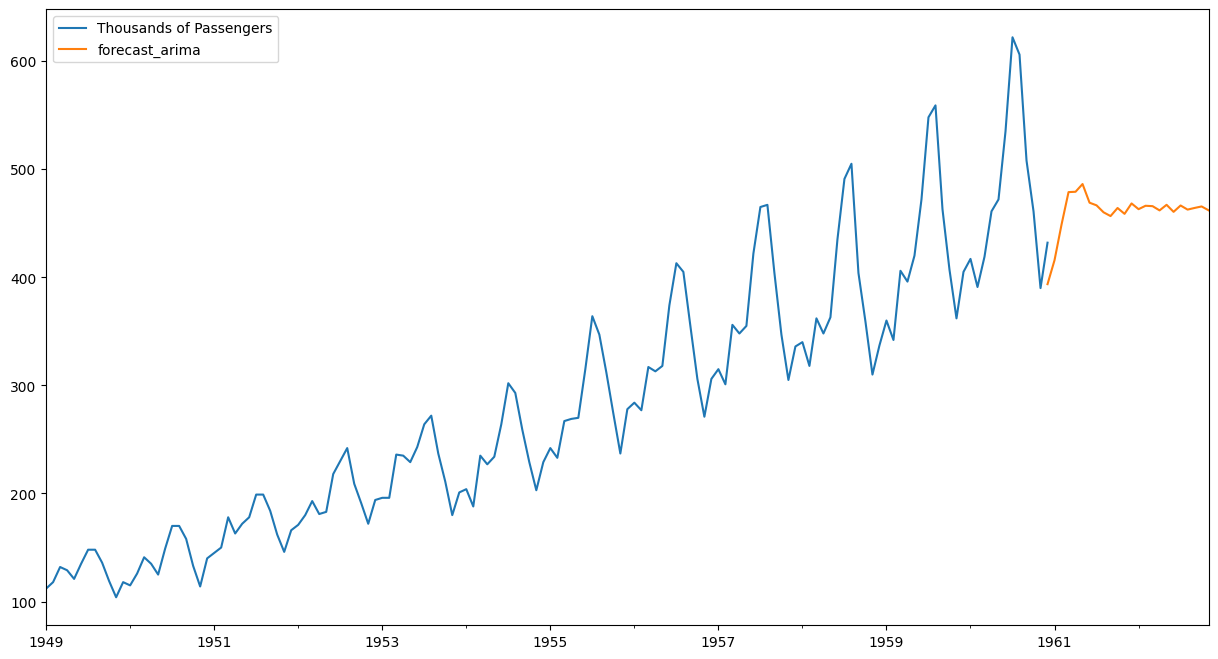

In [72]:
merged_df[['Thousands of Passengers', 'forecast_arima']].plot(figsize = (15, 8))

---

#### 5. Validation

In [73]:
model_Arima_fit.mse

np.float64(807.902765761973)

---

### SARIMA

### The model is written in the notation \(ARIMA(p,d,q)\times (P,D,Q)_{s}\)

**Stationary**

In [77]:
### 12 months 
## Use Techniques Differencing
df_airline["Passengers 12 Difference"]=df_airline["Thousands of Passengers"]-df_airline["Thousands of Passengers"].shift(12) # I = 1

In [78]:
adf_test(df_airline["Passengers 12 Difference"].dropna())

(np.float64(-3.383020726492481), np.float64(0.011551493085514954), 1, 130, {'1%': np.float64(-3.4816817173418295), '5%': np.float64(-2.8840418343195267), '10%': np.float64(-2.578770059171598)}, np.float64(919.527129208137))
ADF Statistics: -3.383020726492481
p- value: 0.011551493085514954
strong evidence against the null hypothesis, reject the null hypothesis. Data has no unit root and is stationary


**ACF and PACF**

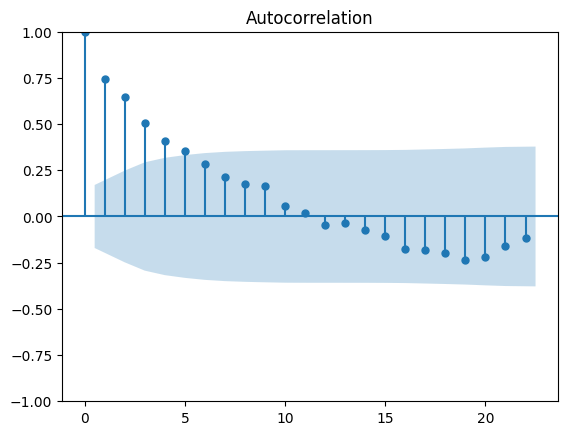

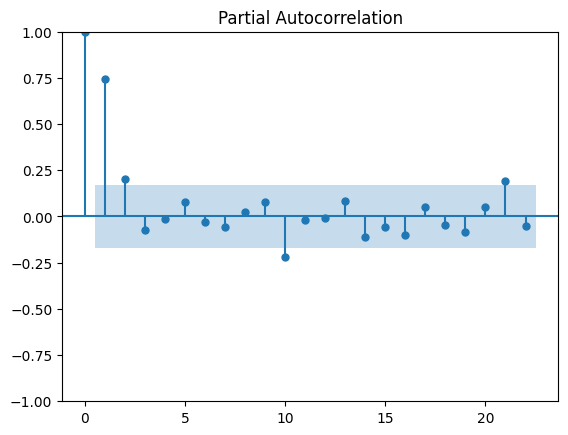

In [79]:
acf12 = plot_acf(df_airline["Passengers 12 Difference"].dropna())
pacf12 = plot_pacf(df_airline["Passengers 12 Difference"].dropna())

p = 4 (1,2,10) <br>
1m = 5 (1,2,3,4,5) <br>
d = 1 <br>
12 <br>

In [80]:
## create a SARIMA model
from statsmodels.tsa.statespace.sarimax import SARIMAX

In [81]:
model_SARIMA=SARIMAX(df_airline['Thousands of Passengers'],order=(1,2,1),seasonal_order=(4,1,5,12))# P,I,Q,F

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [82]:
model_SARIMA_fit=model_SARIMA.fit()

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [83]:
print(model_SARIMA_fit.summary())

                                            SARIMAX Results                                             
Dep. Variable:                          Thousands of Passengers   No. Observations:                  144
Model:             SARIMAX(1, 2, 1)x(4, 1, [1, 2, 3, 4, 5], 12)   Log Likelihood                -499.706
Date:                                          Sun, 01 Mar 2026   AIC                           1023.413
Time:                                                  23:47:34   BIC                           1057.823
Sample:                                              01-01-1949   HQIC                          1037.395
                                                   - 12-01-1960                                         
Covariance Type:                                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar

### Choose The Best Model

In [84]:
#pip install pmdarima
import pmdarima as pm

In [85]:
model = pm.auto_arima(
    df_airline['Thousands of Passengers'], 
    start_p=0, max_p=11,     
    d=2,                     
    start_q=0, max_q=12,     
    seasonal=True, m=12,    
    D=1,                    
    max_P=4, max_Q=5,        
    stepwise=True,           
    trace=True)
print(model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,2,0)(1,1,1)[12]             : AIC=1146.935, Time=0.54 sec
 ARIMA(0,2,0)(0,1,0)[12]             : AIC=1149.749, Time=0.06 sec
 ARIMA(1,2,0)(1,1,0)[12]             : AIC=1079.094, Time=0.35 sec
 ARIMA(0,2,1)(0,1,1)[12]             : AIC=inf, Time=0.93 sec
 ARIMA(1,2,0)(0,1,0)[12]             : AIC=1078.190, Time=0.09 sec
 ARIMA(1,2,0)(0,1,1)[12]             : AIC=1079.232, Time=0.38 sec
 ARIMA(1,2,0)(1,1,1)[12]             : AIC=1080.607, Time=0.82 sec
 ARIMA(2,2,0)(0,1,0)[12]             : AIC=1063.641, Time=0.16 sec
 ARIMA(2,2,0)(1,1,0)[12]             : AIC=1062.635, Time=0.38 sec
 ARIMA(2,2,0)(2,1,0)[12]             : AIC=1062.614, Time=0.83 sec
 ARIMA(2,2,0)(3,1,0)[12]             : AIC=1063.859, Time=1.82 sec
 ARIMA(2,2,0)(2,1,1)[12]             : AIC=inf, Time=5.75 sec
 ARIMA(2,2,0)(1,1,1)[12]             : AIC=1063.105, Time=1.16 sec
 ARIMA(2,2,0)(3,1,1)[12]             : AIC=inf, Time=11.72 sec
 ARIMA(1,2,0)(2,1,0)[12]         

In [86]:
model_SARIMA_fit=SARIMAX(df_airline['Thousands of Passengers'],order=(5,2,0),seasonal_order=(2,1,0,12))# P,I,Q,F

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [87]:
model_SARIMA_fit=model_SARIMA.fit()

C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\Brahim\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [88]:
pred_Sarima=model_SARIMA_fit.predict()
residuals=df_airline['Thousands of Passengers']-pred_Sarima

In [89]:
table = pd.DataFrame({"Real Data": df_airline["Thousands of Passengers"],
"Prediction": pred_Sarima,
"Residuals": residuals})

print(table.head(10))

            Real Data  Prediction   Residuals
1949-01-01      112.0    0.000000  112.000000
1949-02-01      118.0  186.661219  -68.661219
1949-03-01      132.0  124.014273    7.985727
1949-04-01      129.0  145.992756  -16.992756
1949-05-01      121.0  126.007416   -5.007416
1949-06-01      135.0  112.998885   22.001115
1949-07-01      148.0  148.994020   -0.994020
1949-08-01      148.0  161.002372  -13.002372
1949-09-01      136.0  148.002891  -12.002891
1949-10-01      119.0  124.002607   -5.002607


**Residuals Diagnostics**

<Axes: xlabel='Month'>

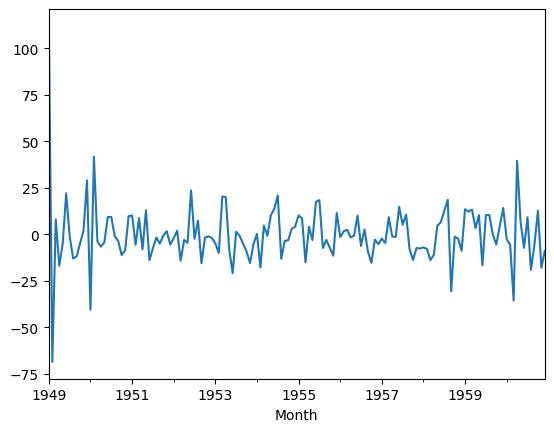

In [91]:
model_SARIMA_fit.resid.plot()

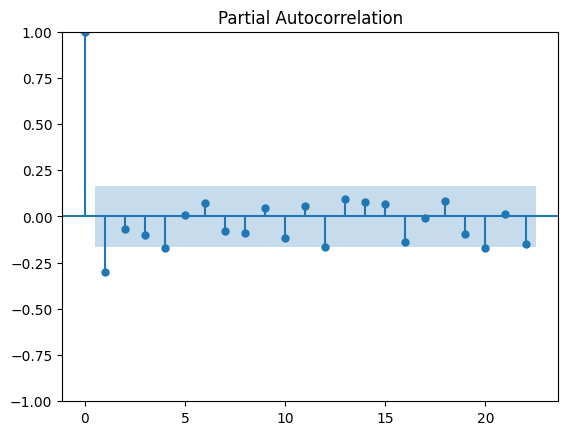

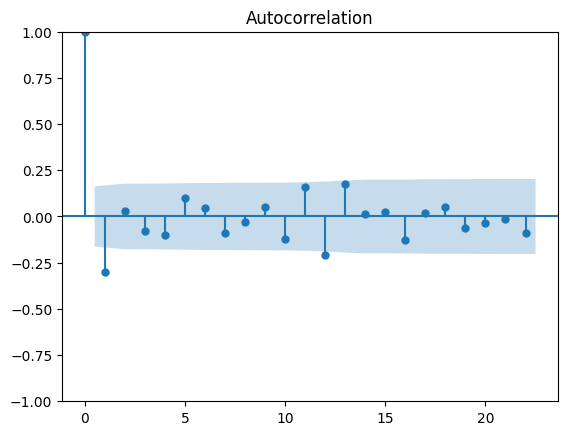

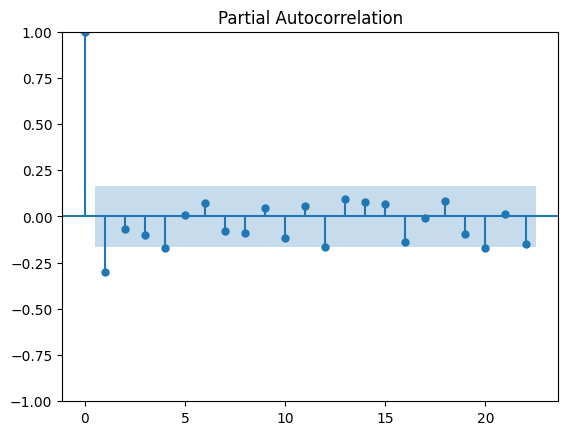

In [92]:
plot_acf(residuals)
plot_pacf(residuals)

<Axes: ylabel='Density'>

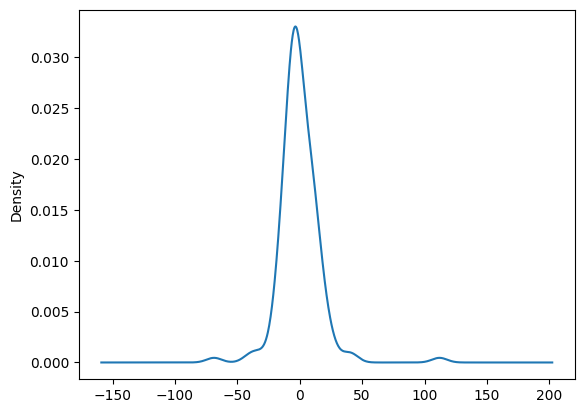

In [93]:
model_SARIMA_fit.resid.plot(kind='kde')

In [94]:
df_airline['Predicted_SARIMA']=pred_Sarima

<Axes: xlabel='Month'>

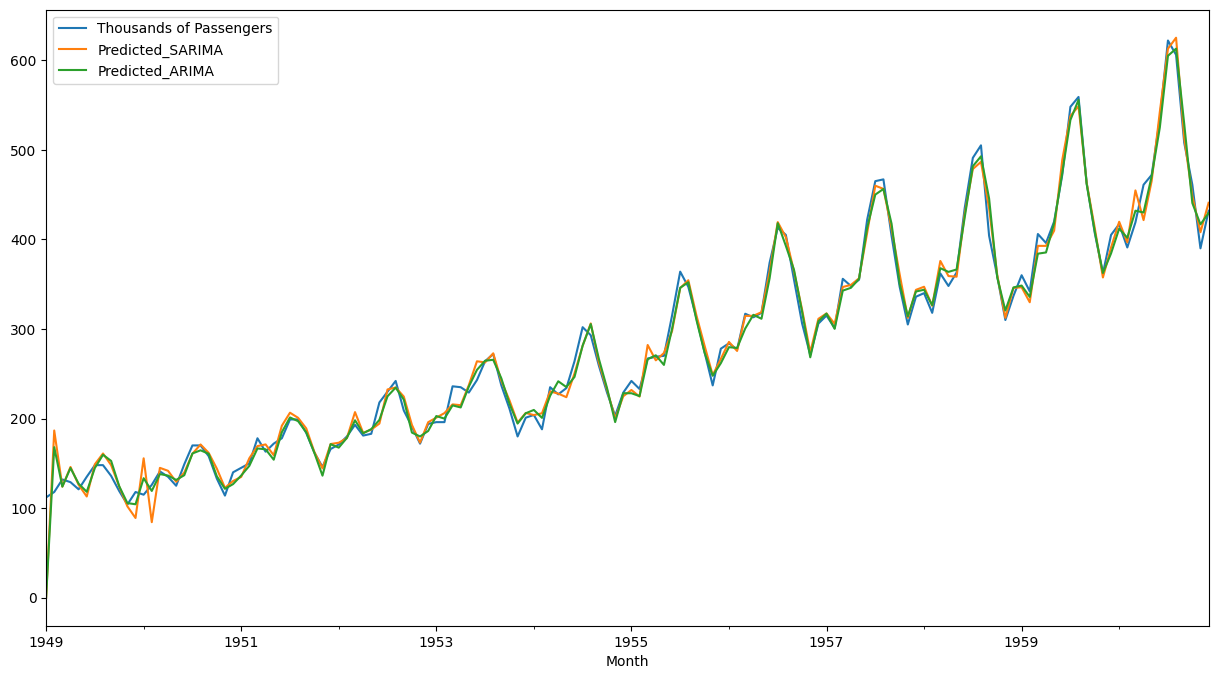

In [95]:
df_airline[['Thousands of Passengers','Predicted_SARIMA','Predicted_ARIMA']].plot(figsize = (15,8))

In [96]:
from pandas.tseries.offsets import DateOffset
future_dates_s = [df_airline.index[-1] + DateOffset (months = x) for x in range(0, 24)]

In [97]:
future_date_dataset = pd.DataFrame(index = future_dates_s[1:], columns = df_airline.columns)
future_date_dataset.tail()
merged_df_s = pd.concat([df_airline, future_date_dataset])
merged_df_s.tail()
df_airline.tail()

,Thousands of Passengers,Passengers First Difference,Passengers Second Difference,Predicted_ARIMA,Passengers 12 Difference,Predicted_SARIMA
Month,,,,,,
1960-08-01,606.0,-16.0,-103.0,612.907531,47.0,625.117908
1960-09-01,508.0,-98.0,-82.0,529.118124,45.0,513.569387
1960-10-01,461.0,-47.0,51.0,440.569567,54.0,448.413209
1960-11-01,390.0,-71.0,-24.0,416.760983,28.0,408.008325
1960-12-01,432.0,42.0,113.0,429.420824,27.0,440.843876


<Axes: >

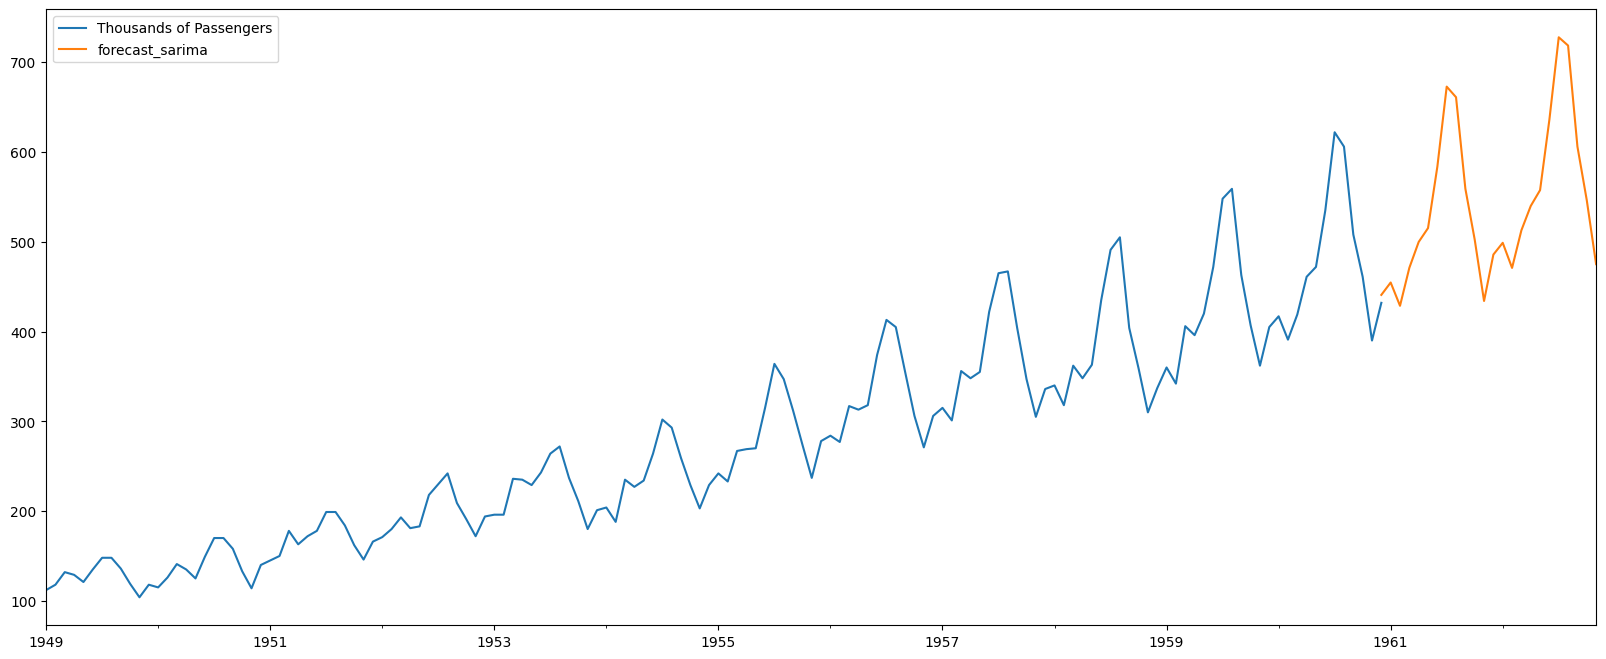

In [99]:
merged_df_s['forecast_sarima'] = model_SARIMA_fit.predict(start ="1960-12-01", end = "1980-11-01", dynamic= True )
merged_df_s[['Thousands of Passengers', 'forecast_sarima']].plot(figsize = (20, 8))

In [100]:
df_airline.tail()

,Thousands of Passengers,Passengers First Difference,Passengers Second Difference,Predicted_ARIMA,Passengers 12 Difference,Predicted_SARIMA
Month,,,,,,
1960-08-01,606.0,-16.0,-103.0,612.907531,47.0,625.117908
1960-09-01,508.0,-98.0,-82.0,529.118124,45.0,513.569387
1960-10-01,461.0,-47.0,51.0,440.569567,54.0,448.413209
1960-11-01,390.0,-71.0,-24.0,416.760983,28.0,408.008325
1960-12-01,432.0,42.0,113.0,429.420824,27.0,440.843876


**Validation**

In [101]:
mse_test_SArima = model_SARIMA_fit.mse
mae_test_SArima = model_SARIMA_fit.mae
print("MSE:", round(mse_test_SArima,3))

MSE: 266.901


In [103]:
print(mse_test_SArima)
print(mse_test_Arima)

266.9013901270586
226.90617951457384
